In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import sklearn
import matplotlib

In [ ]:
sales= pd.read_csv("sales_train_evaluation.csv")

In [ ]:
prices=pd.read_csv("sell_prices.csv")

In [ ]:
cale=pd.read_csv("calendar.csv")

In [ ]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 30490 entries, 0 to 30489
Columns: 1947 entries, id to d_1941
dtypes: int64(1941), str(6)
memory usage: 452.9 MB


In [ ]:
sales.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


In [ ]:

# 🔧 MEMORY GUARD FOR MAC: Focus only on the most recent 300 days of sales history
id_cols = ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
day_cols = [c for c in sales.columns if c.startswith('d_')]
recent_days = day_cols[-300:] 
sales_trimmed = sales[id_cols + recent_days]

print("⏳ Step 2: Running the 'Melt' operation (Turning day columns into rows)...")
master_table = pd.melt(sales_trimmed, id_vars=id_cols, var_name='d', value_name='sales')

# Extract raw numeric day values (e.g., convert 'd_1915' into the integer 1915)
master_table['day_num'] = master_table['d'].str.replace('d_', '').astype(int)

print("⏳ Step 3: Gluing the Calendar Bridge (Day tags -> Week tags)...")
master_table = master_table.merge(cale[['d', 'wm_yr_wk']], on='d', how='left')

print("⏳ Step 4: Injecting the Prices (3-Way Matching Join)...")
master_table = master_table.merge(prices, on=['store_id', 'item_id', 'wm_yr_wk'], how='left')

# Fill any empty price cells with the median price to keep data clean
master_table['sell_price'] = master_table['sell_price'].fillna(master_table['sell_price'].median())

print("⏳ Step 5: Encoding text labels into numeric codes...")
master_table['cat_code'] = master_table['cat_id'].astype('category').cat.codes
master_table['dept_code'] = master_table['dept_id'].astype('category').cat.codes
master_table['store_code'] = master_table['store_id'].astype('category').cat.codes

# Drop old raw text columns to keep the file lightweight and ready for machine learning
master_table = master_table.drop(columns=['cat_id', 'dept_id', 'store_id', 'state_id', 'wm_yr_wk', 'd'])

print("💾 Step 6: Saving your unified dataset to disk...")
master_table.to_csv("master_sales_data.csv", index=False)

print("\n🚀 SUCCESS! One single master table created.")
print(f"📦 Total rows and columns in master_table: {master_table.shape}")
print(master_table.head())


⏳ Step 2: Running the 'Melt' operation (Turning day columns into rows)...
⏳ Step 3: Gluing the Calendar Bridge (Day tags -> Week tags)...
⏳ Step 4: Injecting the Prices (3-Way Matching Join)...
⏳ Step 5: Encoding text labels into numeric codes...
💾 Step 6: Saving your unified dataset to disk...

🚀 SUCCESS! One single master table created.
📦 Total rows and columns in master_table: (9147000, 8)
                              id        item_id  sales  day_num  sell_price  \
0  HOBBIES_1_001_CA_1_evaluation  HOBBIES_1_001      2     1642        8.26   
1  HOBBIES_1_002_CA_1_evaluation  HOBBIES_1_002      2     1642        3.97   
2  HOBBIES_1_003_CA_1_evaluation  HOBBIES_1_003      0     1642        2.97   
3  HOBBIES_1_004_CA_1_evaluation  HOBBIES_1_004      0     1642        4.64   
4  HOBBIES_1_005_CA_1_evaluation  HOBBIES_1_005      1     1642        2.88   

   cat_code  dept_code  store_code  
0         1          3           0  
1         1          3           0  
2         1       

In [ ]:
master_table.shape

(9147000, 8)

this means that the data have 30,490 rows in data nad we have taken 300 days of data so 
300* 30490

In [ ]:
master_table.columns

Index(['id', 'item_id', 'sales', 'day_num', 'sell_price', 'cat_code',
       'dept_code', 'store_code'],
      dtype='str')

array([[<Axes: title={'center': 'sales'}>,
        <Axes: title={'center': 'day_num'}>],
       [<Axes: title={'center': 'sell_price'}>,
        <Axes: title={'center': 'cat_code'}>],
       [<Axes: title={'center': 'dept_code'}>,
        <Axes: title={'center': 'store_code'}>]], dtype=object)

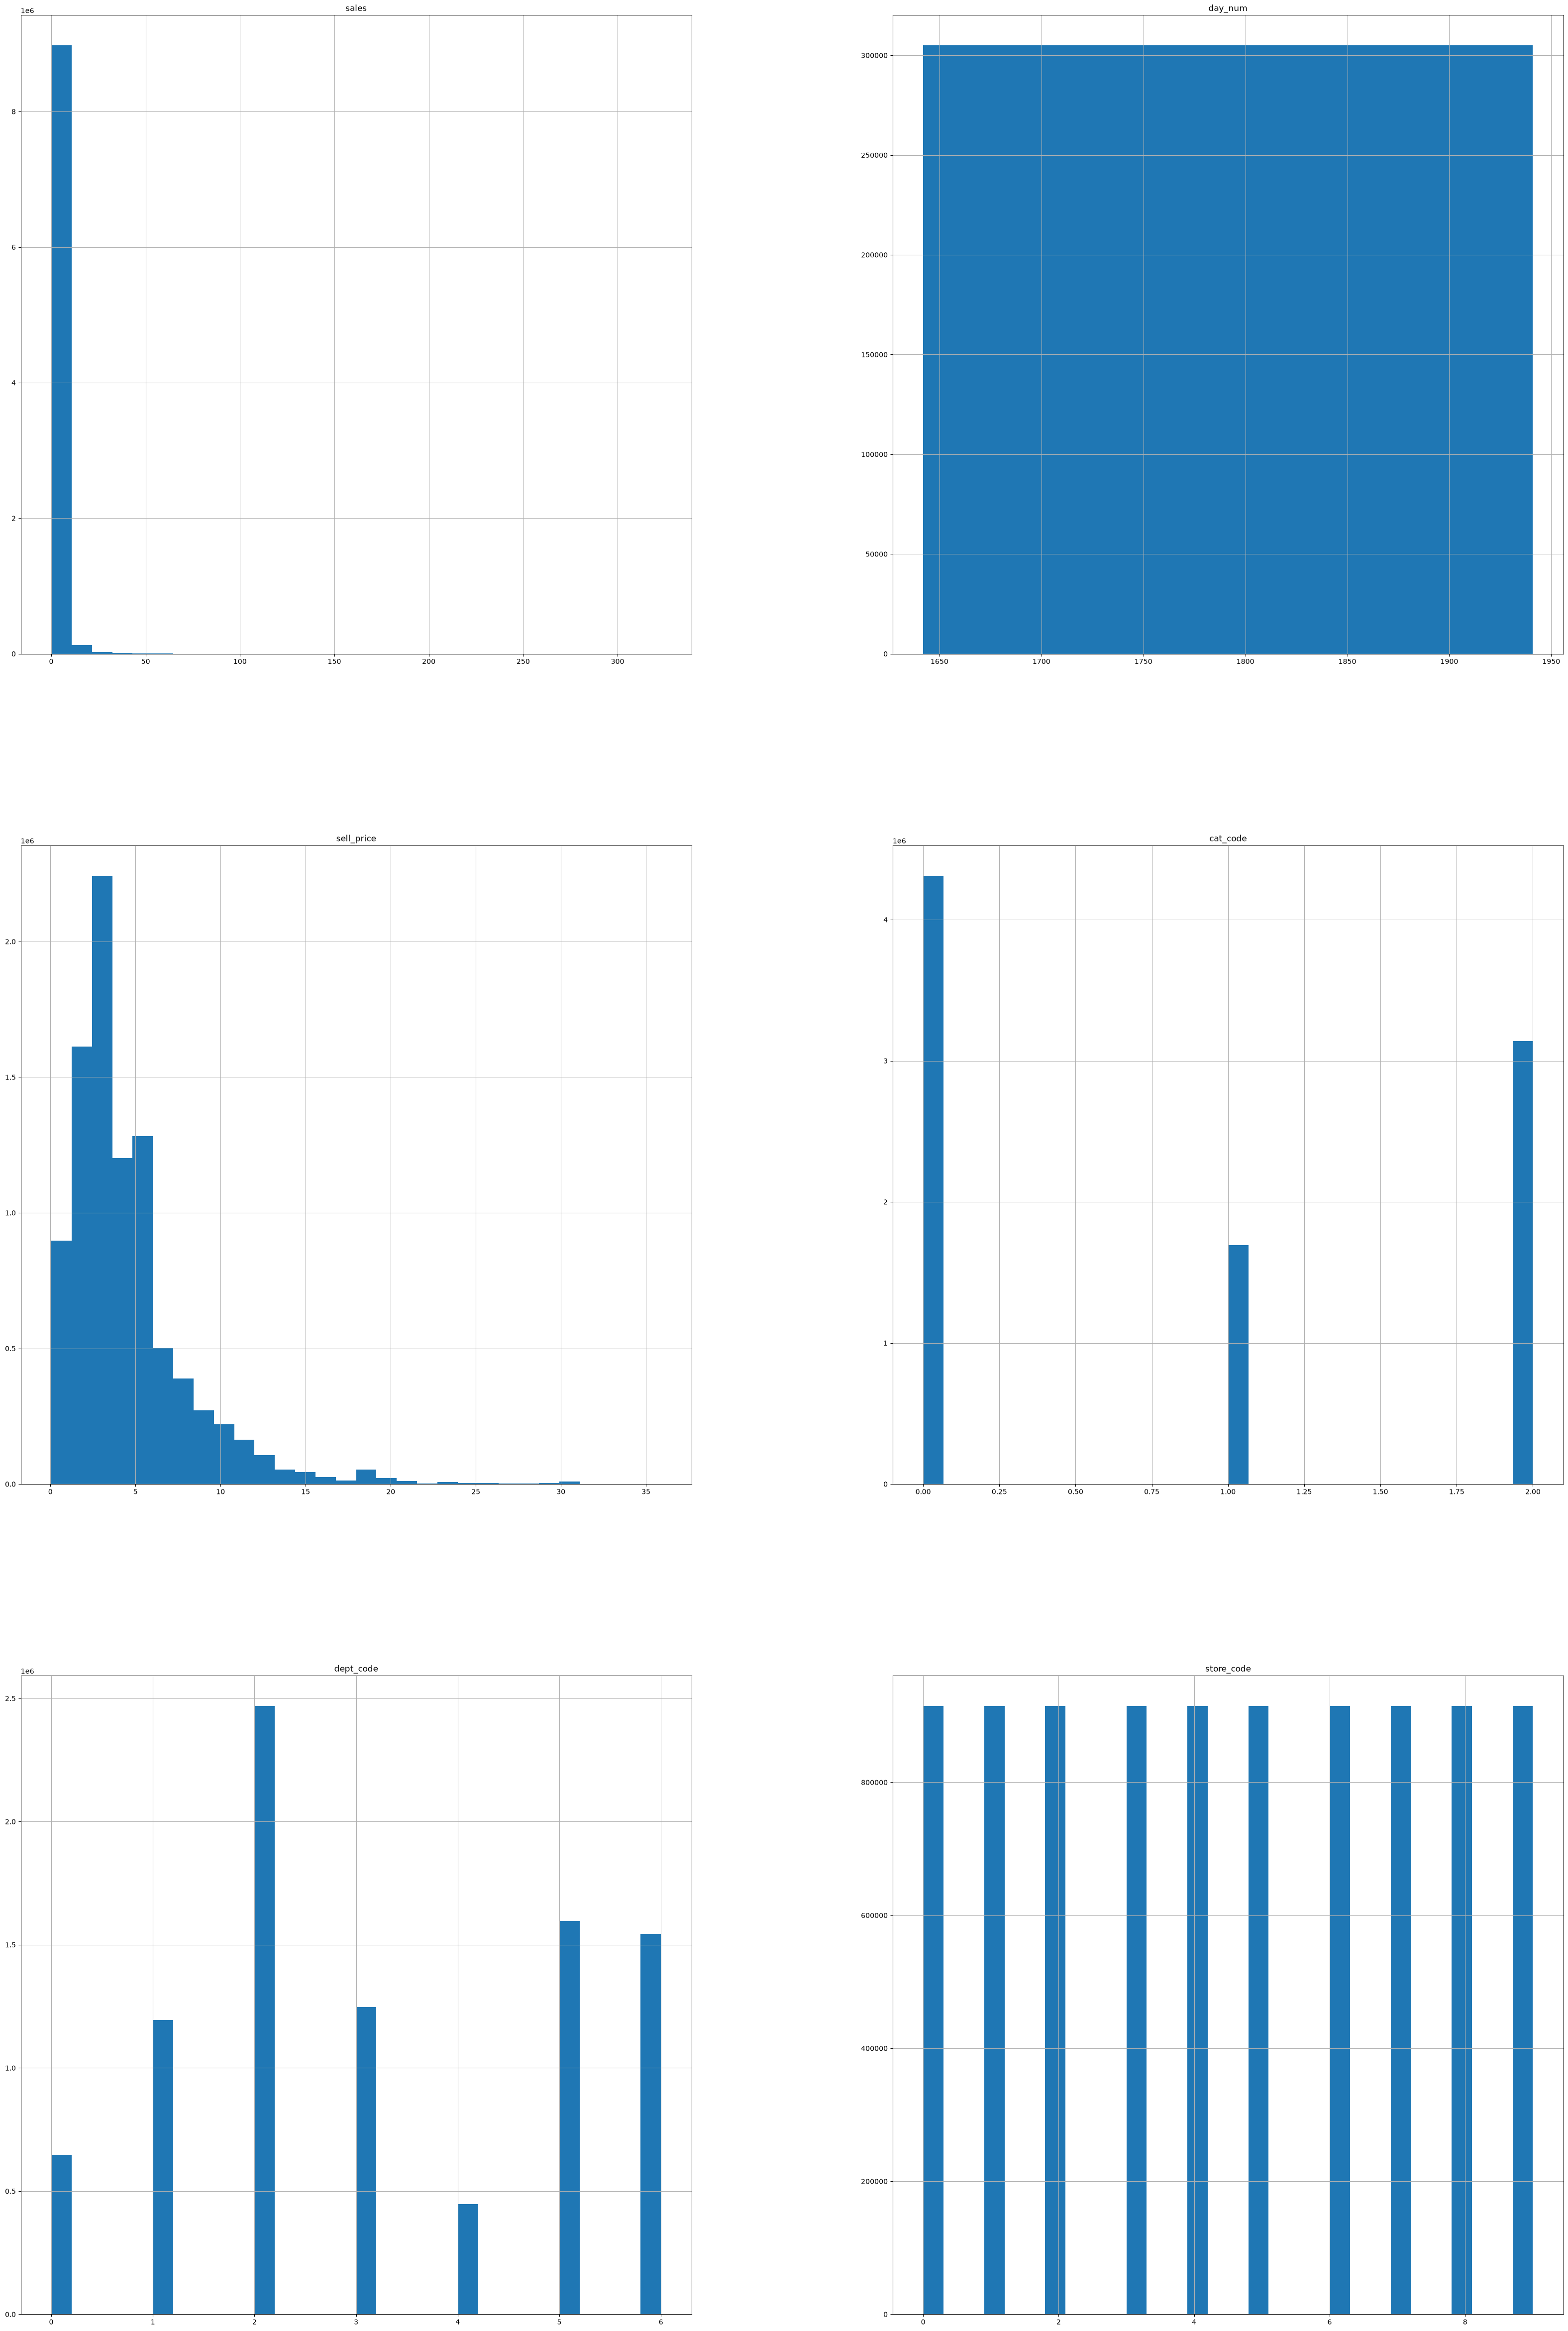

In [ ]:
master_table.hist(bins=30,figsize=(40,60))

In [ ]:
from sklearn.model_selection import train_test_split
train_set,test_set=train_test_split(master_table,test_size=0.2,random_state=42)
print(len(train_set),len(test_set))

7317600 1829400


In [ ]:
from sklearn.model_selection import StratifiedShuffleSplit
split = StratifiedShuffleSplit(n_splits=1,random_state=42,test_size=0.2)
for train_index,test_index in split.split(master_table,master_table='')